# Group cohesion

Roadmap step 2, part 1. How united is each political group when it votes, and has that changed?

Cohesion is measured with the **agreement index** on each roll call:

- (largest position − half of the other positions) / all positions, over For, Against and Abstention;
- 1 means every member who voted took the same position, 0 an even three-way split;
- members marked Did not vote are left out.

The index is the one used by Hix, Noury and Roland (2005), [Power to the Parties](https://doi.org/10.1017/S0007123405000128) (paper confirmed; the formula is unverified against the full text, which is paywalled). It counts abstention as a third position because a group can whip its members to abstain.

A group counts on a roll call only if at least 5 of its members took an active position. Non-attached members aren't a group, so their index is shown only as a reference: it measures how often members without a whip happen to vote alike.

Scope: the 9th term (July 2019 to July 2024) and the 10th term so far (July 2024 to October 2026). Contested roll calls follow the same rule as the USA: the smaller of For and Against is at least 2.5% of the two.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from howtheyvote import load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
CUTOFFS = [0.0, 0.025, 0.10]
# Display order: group means on the first dimension of the agreement maps (notebook 03), the same in both terms.
# Non-attached members aren't a group and come last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
BREXIT = pd.Timestamp("2020-01-31")
TERM_10_START = pd.Timestamp("2024-07-16")


def half_year(dates):
    """Half-years as numbers: 2019.5 is July to December 2019, 2020.0 January to June 2020."""
    return dates.dt.year + (dates.dt.month > 6) * 0.5


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = half_year(rollcalls["date"])

from clustering import MIN_GROUP_VOTES, agreement_index, group_counts

group_frames, delegation_frames = [], []
for term in TERMS:
    votes = load_votes(term)
    group_frames.append(group_counts(votes).reset_index().assign(term=term))
    # National delegations inside each group, for the comparison further down.
    keys = votes["group_code"].astype(str) + "|" + votes["country_code"].astype(str)
    delegation = group_counts(votes.assign(group_code=keys))
    delegation = delegation[delegation.sum(axis=1) >= MIN_GROUP_VOTES]
    delegation = delegation.assign(ai=agreement_index(delegation)).reset_index()
    delegation[["group_code", "country_code"]] = delegation["group_code"].str.split("|", expand=True)
    delegation_frames.append(delegation.assign(term=term))
    del votes
delegations = pd.concat(delegation_frames, ignore_index=True)
groups = pd.concat(group_frames, ignore_index=True)
groups["active"] = groups[["for", "against", "abstention"]].sum(axis=1)
groups = groups[groups["active"] >= MIN_GROUP_VOTES].copy()
groups["group_code"] = groups["group_code"].astype(str)
groups["ai"] = agreement_index(groups)
groups["ai_for_against"] = agreement_index(groups, abstention=False)
groups = groups.join(rollcalls[["half", "vote_part", "minority_share", "minority_share_with_abstention", "date"]], on="vote_id")
contested = groups[groups["minority_share"] >= 0.025]
print(f"{len(groups):,} group-roll-call rows; {len(contested):,} on contested roll calls")
print("Contested roll calls:", contested.groupby("term")["vote_id"].nunique().to_dict())

211,892 group-roll-call rows; 199,518 on contested roll calls
Contested roll calls: {9: 17936, 10: 6226}


## Cohesion by group and term

In [2]:
def mean_ai(frame, column="ai"):
    return frame.groupby(["group_code", "term"])[column].mean().unstack()

table = pd.concat({
    "all roll calls": mean_ai(groups),
    "contested (2.5%)": mean_ai(contested),
    "contested (10%)": mean_ai(groups[groups["minority_share"] >= 0.10]),
    "contested, abstention against (2.5%)": mean_ai(groups[groups["minority_share_with_abstention"] >= 0.025]),
    "contested, For/Against only": mean_ai(contested, "ai_for_against"),
}, axis=1)
table = table.reindex([g for g in GROUP_ORDER if g in table.index]).rename(index=LABELS)
display(table.round(3))

all roll calls        contested (2.5%)        contested (10%)  \
term                     9      10               9      10              9    
group_code                                                                   
Greens/EFA            0.968  0.938            0.966  0.937           0.964   
The Left              0.853  0.876            0.849  0.875           0.860   
S&D                   0.926  0.930            0.920  0.929           0.908   
Renew                 0.888  0.914            0.881  0.912           0.862   
EPP                   0.895  0.888            0.887  0.885           0.869   
ECR                   0.795  0.812            0.787  0.809           0.788   
ID                    0.656    NaN            0.651    NaN           0.686   
PfE                     NaN  0.767              NaN  0.765             NaN   
ESN                     NaN  0.852              NaN  0.854             NaN   
Non-attached          0.465  0.426            0.445  0.421           0.415   

                    contested, abstention against (2.5%)         \
term             10                                   9      10   
group_code                                                        
Greens/EFA    0.935                                0.967  0.938   
The Left      0.879                                0.850  0.875   
S&D           0.925                                0.924  0.930   
Renew         0.907                                0.886  0.913   
EPP           0.878                                0.892  0.887   
ECR           0.807                                0.791  0.811   
ID              NaN                                0.650    NaN   
PfE           0.771                                  NaN  0.766   
ESN           0.863                                  NaN  0.852   
Non-attached  0.417                                0.457  0.424   

             contested, For/Against only         
term                                  9      10  
group_code                                       
Greens/EFA                         0.978  0.961  
The Left                           0.913  0.934  
S&D                                0.938  0.947  
Renew                              0.905  0.930  
EPP                                0.914  0.913  
ECR                                0.864  0.896  
ID                                 0.806    NaN  
PfE                                  NaN  0.884  
ESN                                  NaN  0.921  
Non-attached                       0.589  0.609

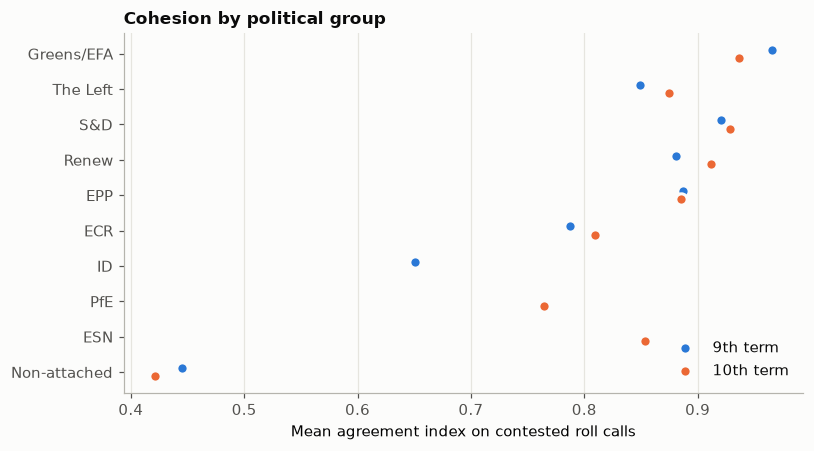

In [3]:
main = mean_ai(contested).reindex([g for g in GROUP_ORDER if g in contested["group_code"].unique()])
fig, axis = plt.subplots(figsize=(7.5, 4.2))
positions = np.arange(len(main))[::-1]
for column, (term, color) in enumerate(zip(TERMS, SERIES)):
    values = main[term]
    offset = 0.12 if term == 9 else -0.12
    axis.scatter(values, positions + offset, s=55, color=color, label=f"{term}th term", zorder=3,
                 edgecolor="#fcfcfb", linewidth=2)
axis.set_yticks(positions, [LABELS[g] for g in main.index])
axis.set_xlabel("Mean agreement index on contested roll calls")
axis.legend(loc="lower right")
axis.set_title("Cohesion by political group")
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**What this shows**

- **Greens/EFA and S&D are the most cohesive groups in both terms** on contested roll calls (0.966 and 0.937; 0.920 and 0.929).
- **Renew, the EPP and The Left come next, between 0.85 and 0.92.** Their order changes between terms: the EPP is just above Renew in the 9th term (0.887 against 0.881) and below it in the 10th (0.885 against 0.912).
- **The groups to the right of the EPP are less cohesive:** ECR at 0.787 and 0.809, Identity and Democracy at 0.651 in the 9th term, and Patriots for Europe at 0.765 in the 10th. Europe of Sovereign Nations, the smallest group, is higher (0.854).
- **Changes between terms are small,** at most about 0.03 for groups present in both: The Left and Renew up, Greens/EFA down. The two terms vote on different roll calls, and group membership changed, so these are differences in behaviour on different agendas, not a like-for-like change.
- **The cutoff and the abstention rule move every group by 0.035 or less.** The broad pattern holds under all of them, with the centre groups above ECR, ID and PfE. Close neighbours can swap: at 10% in the 10th term The Left (0.879) edges past the EPP (0.878).
- **Abstention explains part of the gap.** Counting only For and Against raises every group, most for ECR (to 0.864 and 0.896), ID (0.806) and PfE (0.884). Part of these groups' lower cohesion is members splitting between a position and abstaining.
- Non-attached members (0.445 and 0.421) agree far less than any group, as expected for members without a whip. They are a reference, not a group.

## Abstention as a group line

How often each group's most common position is to abstain, on contested roll calls. This is why the index counts three positions.

In [4]:
from clustering import group_line

lines = contested.set_index(["vote_id", "group_code"])
lines = lines.assign(line=group_line(lines))
abstain = lines.groupby(["group_code", "term"])["line"].apply(lambda s: s.eq("ABSTENTION").mean()).unstack()
abstain = abstain.reindex([g for g in GROUP_ORDER if g in abstain.index and g != "NI"]).rename(index=LABELS)
display((abstain * 100).round(1).rename(columns=lambda t: f"{t}th term, % of lines"))

term,"9th term, % of lines","10th term, % of lines"
group_code,,
Greens/EFA,2.7,4.1
The Left,3.0,2.9
S&D,1.4,1.9
Renew,0.5,0.4
EPP,0.7,0.5
ECR,9.9,6.9
ID,11.6,NaN
PfE,NaN,8.2
ESN,NaN,7.9


**Abstaining is a group line mainly for the groups to the right of the EPP.** ECR, ID, PfE and ESN abstain as a group on 7% to 12% of contested roll calls. S&D, Renew and the EPP do so on under 2%, and The Left and Greens/EFA on 3% to 4%. A For/Against measure would treat these as non-votes and miss the line.

## Cohesion over time

Mean agreement index on contested roll calls in each half-year. The grey lines mark the UK's departure (31 January 2020) and the start of the 10th term (16 July 2024).

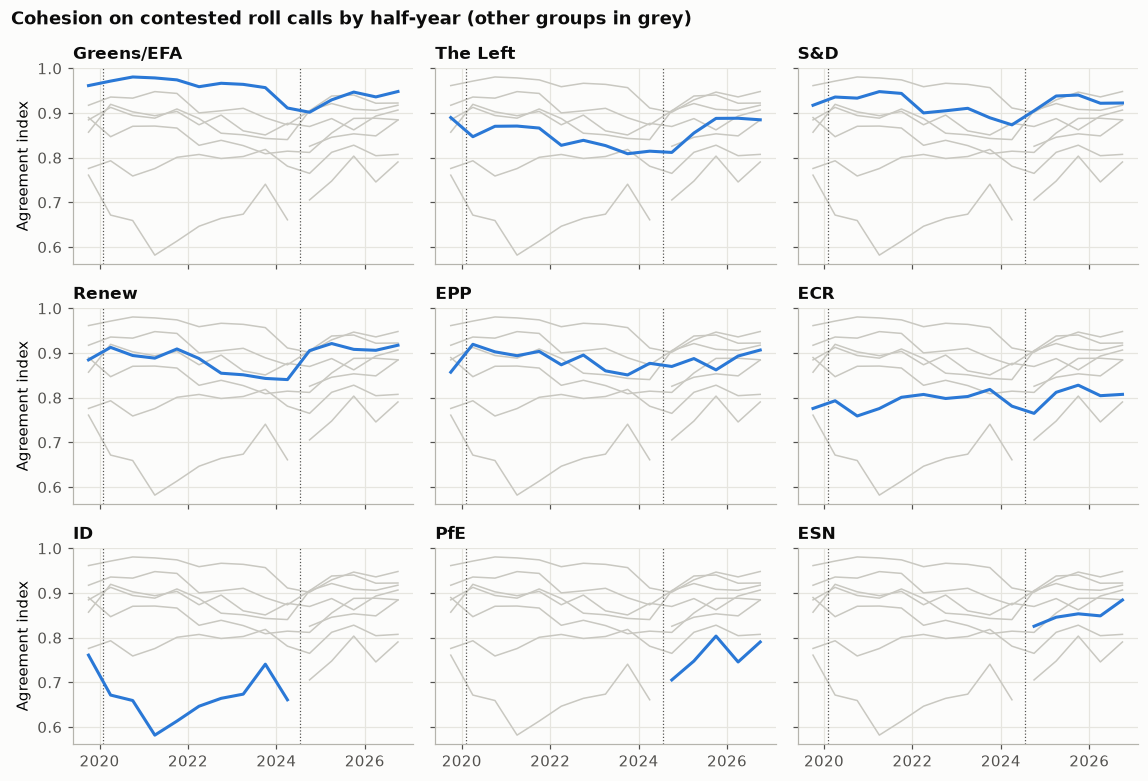

group_code,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID,PfE,ESN,Non-attached,contested roll calls
half,,,,,,,,,,,
2019 H2,0.961,0.890,0.917,0.885,0.857,0.776,0.761,NaN,NaN,0.400,499
2020 H1,0.972,0.847,0.936,0.913,0.920,0.793,0.672,NaN,NaN,0.590,1292
2020 H2,0.981,0.870,0.933,0.894,0.903,0.759,0.659,NaN,NaN,0.573,3484
2021 H1,0.979,0.871,0.948,0.889,0.894,0.776,0.582,NaN,NaN,0.447,3488
2021 H2,0.974,0.866,0.944,0.909,0.904,0.801,0.613,NaN,NaN,0.407,1608
2022 H1,0.959,0.828,0.900,0.888,0.874,0.807,0.647,NaN,NaN,0.377,2310
2022 H2,0.967,0.839,0.905,0.855,0.895,0.798,0.664,NaN,NaN,0.364,987
2023 H1,0.964,0.827,0.911,0.851,0.860,0.803,0.674,NaN,NaN,0.365,1104
2023 H2,0.957,0.809,0.889,0.843,0.851,0.819,0.741,NaN,NaN,0.357,1574


In [5]:
by_half = contested.groupby(["group_code", "half"]).agg(ai=("ai", "mean"), rollcalls=("vote_id", "nunique")).reset_index()
shown = [g for g in GROUP_ORDER if g != "NI"]
fig, axes = plt.subplots(3, 3, figsize=(10.5, 7.2), sharex=True, sharey=True)
for axis, group in zip(axes.flat, shown):
    data = by_half[by_half["group_code"] == group]
    for other in shown:
        if other != group:
            background = by_half[by_half["group_code"] == other]
            axis.plot(background["half"] + 0.25, background["ai"], color=MUTED, linewidth=1, zorder=1)
    axis.plot(data["half"] + 0.25, data["ai"], color=SERIES[0], zorder=3)
    for date in [BREXIT, TERM_10_START]:
        axis.axvline(date.year + date.day_of_year / 365, color=NEUTRAL, linewidth=0.8, linestyle=":")
    axis.set_title(LABELS[group])
for axis in axes[:, 0]:
    axis.set_ylabel("Agreement index")
fig.suptitle("Cohesion on contested roll calls by half-year (other groups in grey)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
plt.show()
table = by_half.pivot(index="half", columns="group_code", values="ai")[[g for g in GROUP_ORDER if g in by_half["group_code"].unique()]]
table["contested roll calls"] = contested.groupby("half")["vote_id"].nunique()
display(table.rename(index=half_label, columns=LABELS).round(3))

**What this shows**

- **Most groups are steady within a term:** most changes between consecutive half-years are under 0.05.
- **Identity and Democracy was the least stable.** Its index fell from 0.761 in the second half of 2019 to 0.582 in the first half of 2021, then recovered to between 0.61 and 0.74.
- **Several groups were at their lowest just before the 2024 election.** Greens/EFA reached its lowest of the 9th term in the first half of 2024 (0.911). S&D (0.874) and Renew (0.841) also reached their lowest of the 9th term then, and The Left reached its lowest (0.809) in the half-year before. Whether this is campaign behaviour or the mix of votes at the end of a term isn't tested here.
- **Patriots for Europe has become more cohesive since it formed:** 0.705 in its first half-year, then between 0.746 and 0.804.
- The first half-year of each term has fewer contested roll calls (499 and 489), so it is less precise.

## Cohesion by kind of roll call

Final votes on a whole text against amendments and separate votes on parts of a text (see the [vote parts](../../data_loading/docs/README.md#vote-parts) in the data loading docs).

In [6]:
parts = contested[contested["vote_part"].isin(["final", "amendment", "text part"])]
by_part = parts.groupby(["term", "group_code", "vote_part"])["ai"].mean().unstack()
by_part = by_part.reindex(pd.MultiIndex.from_product([TERMS, [g for g in GROUP_ORDER if g != "NI"]]))
by_part = by_part.dropna(how="all").rename(index=LABELS, level=1)
display(by_part.round(3))
print("Contested roll calls by part:")
print(parts.drop_duplicates("vote_id").groupby(["term", "vote_part"]).size().unstack())

vote_part      amendment  final  text part
9  Greens/EFA      0.959  0.962      0.981
   The Left        0.864  0.748      0.850
   S&D             0.899  0.947      0.954
   Renew           0.875  0.898      0.882
   EPP             0.905  0.893      0.844
   ECR             0.804  0.706      0.775
   ID              0.685  0.581      0.593
10 Greens/EFA      0.928  0.918      0.972
   The Left        0.905  0.775      0.833
   S&D             0.920  0.933      0.953
   Renew           0.916  0.876      0.915
   EPP             0.895  0.897      0.847
   ECR             0.838  0.734      0.762
   PfE             0.803  0.704      0.682
   ESN             0.857  0.856      0.843

Contested roll calls by part:
vote_part  amendment  final  text part
term                                  
9              10587   1470       5248
10              3994    609       1444


**Final votes split some groups more than amendments do.** On final votes, The Left (0.748 and 0.775), ECR (0.706 and 0.734), ID (0.581) and PfE (0.704) are about 0.1 less cohesive than on amendments. S&D goes the other way, more united on final votes than on amendments (0.947 and 0.933, against 0.899 and 0.920). The EPP is least united on separate votes on parts of a text (0.844 and 0.847). Final votes are fewer (1,470 and 609 contested).

So the groups at the two ends of the ordering hold together on amendments but divide more over whether to support a whole text.

## National delegations inside groups

Groups are made of national parties elected in national elections. Here each group is split into its national delegations, those of at least 5 active members on a roll call, and the delegation's agreement index is compared with the whole group's on the same roll calls.

In [7]:
delegation_contested = delegations.join(rollcalls["minority_share"], on="vote_id")
delegation_contested = delegation_contested[delegation_contested["minority_share"] >= 0.025]
paired = delegation_contested.merge(contested[["vote_id", "group_code", "ai", "for", "against", "abstention"]],
                                    on=["vote_id", "group_code"], suffixes=("_delegation", "_group"))
# Null: a random set of the same number of members from the same group on the same roll call. Small sets agree
# more by chance, so the delegation is compared with this, not only with the whole group.
rng = np.random.default_rng(0)
group_positions = paired[["for_group", "against_group", "abstention_group"]].to_numpy()
sizes = paired[["for_delegation", "against_delegation", "abstention_delegation"]].sum(axis=1).to_numpy()
draws = np.array([rng.multivariate_hypergeometric(colors, size) for colors, size in zip(group_positions, sizes)])
paired["ai_random"] = agreement_index(pd.DataFrame(draws, columns=["for", "against", "abstention"])).to_numpy()
comparison = paired.groupby(["term", "group_code"]).agg(
    delegations=("country_code", "nunique"),
    delegation_ai=("ai_delegation", "mean"),
    group_ai=("ai_group", "mean"),
)
comparison["gap"] = comparison["delegation_ai"] - comparison["group_ai"]
# Coverage: the share of the group's active positions that fall in delegations large enough to count.
in_delegations = paired.assign(active=sizes).groupby(["term", "group_code", "vote_id"])["active"].sum()
group_active = contested.set_index(["term", "group_code", "vote_id"])["active"]
coverage = (in_delegations / group_active.reindex(in_delegations.index)).groupby(["term", "group_code"]).mean()
all_rollcalls = (in_delegations.groupby(["term", "group_code"]).size()
                 / contested.groupby(["term", "group_code"]).size().reindex(coverage.index))
comparison["coverage_when_present"] = coverage
comparison["rollcalls_with_a_delegation"] = all_rollcalls
comparison["random_ai"] = paired.groupby(["term", "group_code"])["ai_random"].mean()
comparison["gap_over_random"] = comparison["delegation_ai"] - comparison["random_ai"]
comparison = comparison.reindex(pd.MultiIndex.from_product([TERMS, GROUP_ORDER])).dropna(how="all")
display(comparison.rename(index=LABELS, level=1).round(3))

delegations  delegation_ai  group_ai    gap  \
9  Greens/EFA            3.0          0.984     0.966  0.018   
   The Left              4.0          0.961     0.859  0.102   
   S&D                  13.0          0.975     0.923  0.052   
   Renew                 8.0          0.947     0.882  0.065   
   EPP                  16.0          0.951     0.890  0.061   
   ECR                   4.0          0.963     0.787  0.176   
   ID                    3.0          0.985     0.650  0.335   
   Non-attached          5.0          0.888     0.421  0.468   
10 Greens/EFA            3.0          0.977     0.936  0.041   
   The Left              2.0          0.977     0.876  0.101   
   S&D                   8.0          0.978     0.929  0.049   
   Renew                 7.0          0.942     0.914  0.029   
   EPP                  16.0          0.941     0.886  0.055   
   ECR                   3.0          0.945     0.809  0.135   
   PfE                   7.0          0.979     0.765  0.214   
   ESN                   1.0          0.961     0.854  0.107   
   Non-attached          2.0          0.737     0.423  0.314   

                 coverage_when_present  rollcalls_with_a_delegation  \
9  Greens/EFA                    0.531                        1.000   
   The Left                      0.494                        0.978   
   S&D                           0.748                        1.000   
   Renew                         0.645                        1.000   
   EPP                           0.796                        1.000   
   ECR                           0.560                        1.000   
   ID                            0.817                        1.000   
   Non-attached                  0.546                        0.998   
10 Greens/EFA                    0.447                        1.000   
   The Left                      0.424                        1.000   
   S&D                           0.692                        1.000   
   Renew                         0.543                        1.000   
   EPP                           0.785                        1.000   
   ECR                           0.611                        1.000   
   PfE                           0.852                        1.000   
   ESN                           0.565                        1.000   
   Non-attached                  0.487                        0.999   

                 random_ai  gap_over_random  
9  Greens/EFA        0.966            0.018  
   The Left          0.870            0.090  
   S&D               0.925            0.050  
   Renew             0.888            0.059  
   EPP               0.895            0.056  
   ECR               0.795            0.168  
   ID                0.670            0.315  
   Non-attached      0.474            0.414  
10 Greens/EFA        0.938            0.039  
   The Left          0.881            0.097  
   S&D               0.931            0.047  
   Renew             0.917            0.025  
   EPP               0.892            0.050  
   ECR               0.818            0.127  
   PfE               0.788            0.191  
   ESN               0.855            0.106  
   Non-attached      0.482            0.255

**What this shows**

- **National delegations are more united than their group** in every group.
  - Gap over a random draw of the same size: 0.02 to 0.06 for Greens/EFA, S&D, Renew and the EPP.
  - About 0.1 for The Left and ESN.
  - Largest for ECR (0.17 and 0.13), PfE (0.19) and ID (0.32).
- **This isn't a size effect.** Random sets of the same size from the same group agree at most 0.03 more than the whole group, outside the non-attached members.
- **This fits splits along national lines,** especially in ECR, ID and PfE. But high agreement inside delegations doesn't measure how much of a group's disagreement lies between delegations, so it isn't a decomposition.

**Limits**

- A delegation here is all of a group's members from one country, which can include several national parties.
- Only delegations with at least 5 active members on a roll call count. They cover 42% to 85% of each group's active positions on the roll calls where they count, least for Greens/EFA and The Left and most for the EPP, ID and PfE.

## Summary

- Groups vote cohesively. On contested roll calls the mean agreement index is 0.85 to 0.97 for the five groups from Greens/EFA to the EPP, in both terms.
- The groups to the right of the EPP are less cohesive: ECR about 0.8, ID 0.65 in the 9th term, PfE 0.77 in the 10th. Their national delegations agree much more than the group as a whole, and they abstain as a group more often.
- The broad pattern holds across terms, half-years, cutoffs and the abstention rule, though neighbouring groups with similar values can swap places.
- Final votes divide the groups at the two ends of the ordering more than amendments do.